# Lab 8 Task: Edge Detection

**Name:** Abdulsamad Mousa Tuhaishi  
**ID:** 2240001093




In [1]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt

imgDir = 'images'
imgFiles = ['coffee.png', 'cat.png']

if not all(os.path.exists(os.path.join(imgDir, f)) for f in imgFiles):
    from skimage import data
    os.makedirs(imgDir, exist_ok=True)
    cv2.imwrite(os.path.join(imgDir, 'coffee.png'), cv2.cvtColor(data.coffee(), cv2.COLOR_RGB2BGR))
    cv2.imwrite(os.path.join(imgDir, 'cat.png'), cv2.cvtColor(data.chelsea(), cv2.COLOR_RGB2BGR))

images, blurred_images = {}, {}
for f in imgFiles:
    img = cv2.imread(os.path.join(imgDir, f))
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    images[f] = img
    blurred_images[f] = cv2.GaussianBlur(gray, (5, 5), 0)   # same 5x5 blur as the reference notebook
    print(f, 'size (h, w, channels):', img.shape)

coffee.png size (h, w, channels): (400, 600, 3)
cat.png size (h, w, channels): (300, 451, 3)


## Task 1: Sobel, Prewitt and Canny

Each detector is a function so it can run on both images, and all three use the same blurred grayscale input.

Unlike the reference notebook, I convert the magnitude to 8-bit with `cv2.convertScaleAbs`, which caps values at 255. `np.uint8(np.absolute(...))` wraps them instead (300 becomes 44), which leaves dark spots inside the strongest edges.

In [2]:
def sobel_edges(blurred):
    gx = cv2.Sobel(blurred, cv2.CV_64F, 1, 0, ksize=3)
    gy = cv2.Sobel(blurred, cv2.CV_64F, 0, 1, ksize=3)
    return cv2.magnitude(gx, gy)


def prewitt_edges(blurred):
    # OpenCV has no Prewitt function, so the kernels are defined by hand
    kernel_x = np.array([[-1, 0, 1],
                         [-1, 0, 1],
                         [-1, 0, 1]], dtype=np.float64)
    kernel_y = np.array([[-1, -1, -1],
                         [ 0,  0,  0],
                         [ 1,  1,  1]], dtype=np.float64)
    gx = cv2.filter2D(blurred, cv2.CV_64F, kernel_x)
    gy = cv2.filter2D(blurred, cv2.CV_64F, kernel_y)
    return cv2.magnitude(gx, gy)


def canny_edges(blurred, low=100, high=200):
    return cv2.Canny(blurred, low, high)

### Original images and edge maps

Canny uses the reference notebook's 100 / 200 thresholds here.

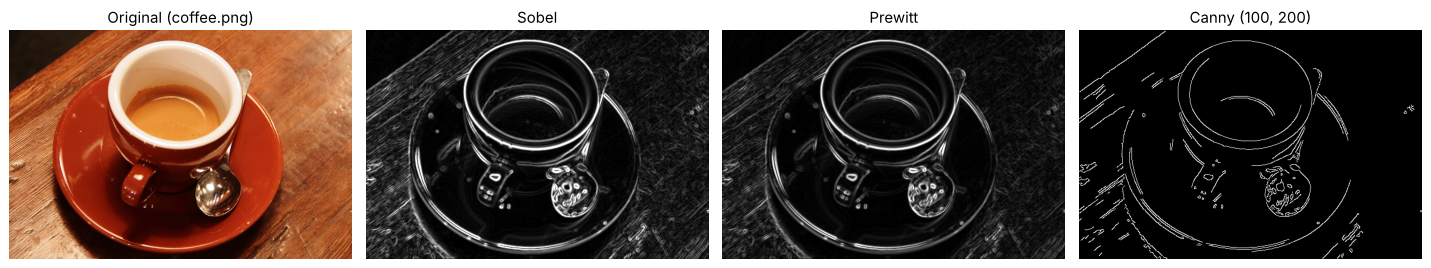

coffee.png: mean gradient magnitude  Sobel = 34.7,  Prewitt = 25.6


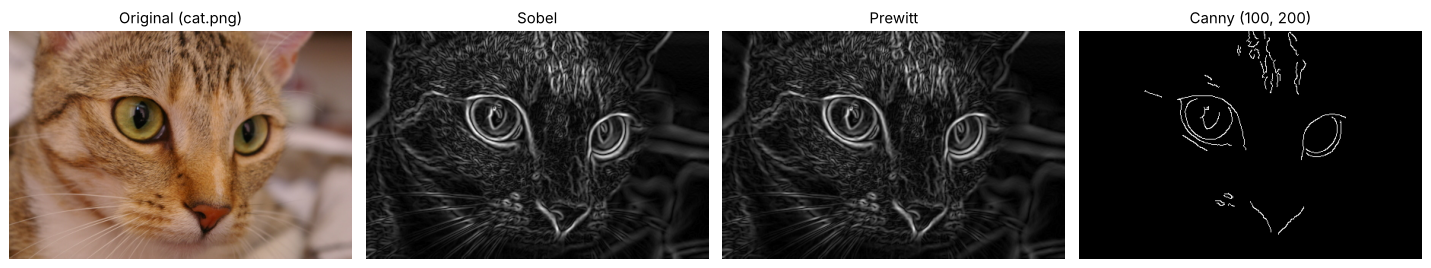

cat.png: mean gradient magnitude  Sobel = 33.7,  Prewitt = 25.1


In [3]:
for f in imgFiles:
    img, blurred = images[f], blurred_images[f]

    sobel_mag = sobel_edges(blurred)
    prewitt_mag = prewitt_edges(blurred)

    plt.figure(figsize=(16, 4))
    plt.subplot(1, 4, 1), plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB)), plt.title(f'Original ({f})'), plt.axis('off')
    plt.subplot(1, 4, 2), plt.imshow(cv2.convertScaleAbs(sobel_mag), cmap='gray'), plt.title('Sobel'), plt.axis('off')
    plt.subplot(1, 4, 3), plt.imshow(cv2.convertScaleAbs(prewitt_mag), cmap='gray'), plt.title('Prewitt'), plt.axis('off')
    plt.subplot(1, 4, 4), plt.imshow(canny_edges(blurred), cmap='gray'), plt.title('Canny (100, 200)'), plt.axis('off')
    plt.tight_layout()
    plt.show()

    print(f'{f}: mean gradient magnitude  Sobel = {sobel_mag.mean():.1f},  Prewitt = {prewitt_mag.mean():.1f}')

### Comparison

Sobel and Prewitt look almost the same: grey magnitude maps with edges a few pixels wide. Sobel is brighter because its kernel weights the rows 1, 2, 1 instead of 1, 1, 1 (mean 34.7 vs 25.6 for the coffee image, 33.7 vs 25.1 for the cat).

Canny thins edges to one pixel and keeps or drops each one using two thresholds, so it gives a black-and-white outline. That works well for the cup, but on the cat 100 / 200 keeps only the eyes, nose and a few stripes, because fur has many weak gradients and few strong ones. Sobel and Prewitt still show the fur as grey texture since they don't discard anything.

## Task 2: Effect of Canny thresholds

I also count the edge pixels in each map so the pairs can be compared with numbers.

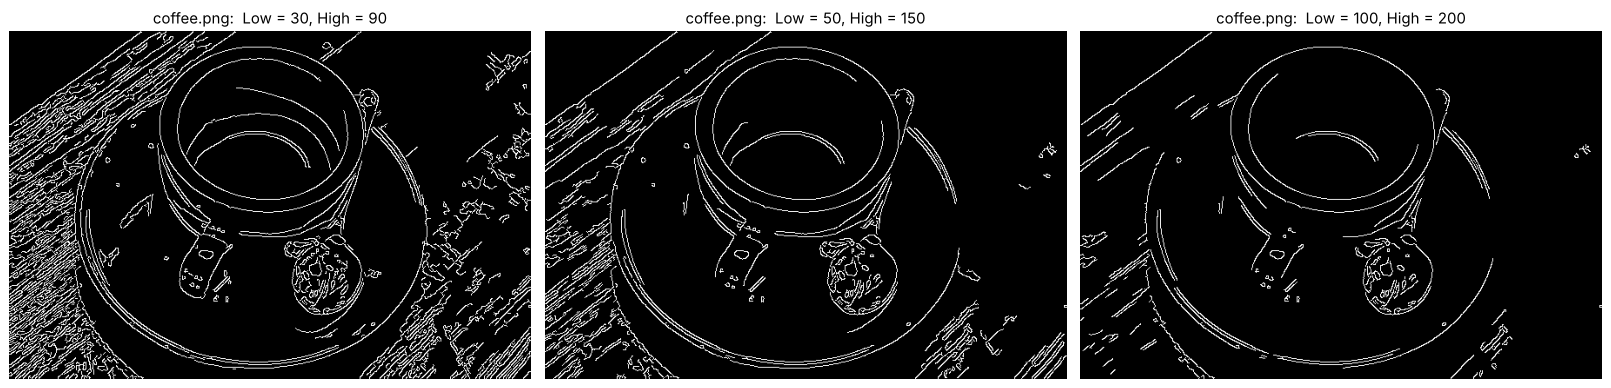

coffee.png  Low =  30, High =  90:   24319 edge pixels  (10.13% of the image)
coffee.png  Low =  50, High = 150:   13823 edge pixels  (5.76% of the image)
coffee.png  Low = 100, High = 200:    7790 edge pixels  (3.25% of the image)



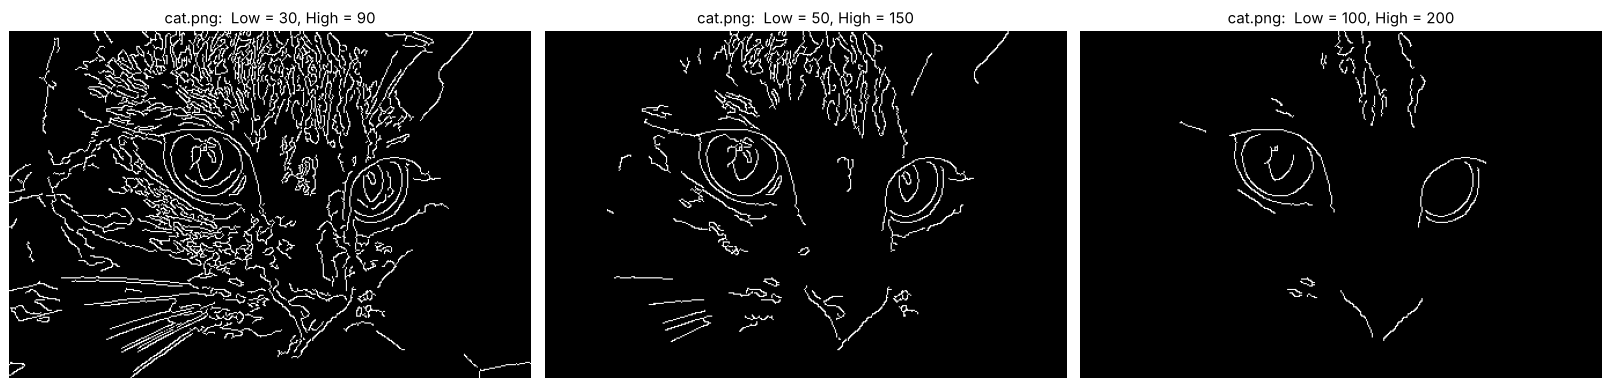

cat.png  Low =  30, High =  90:   13614 edge pixels  (10.06% of the image)
cat.png  Low =  50, High = 150:    4941 edge pixels  (3.65% of the image)
cat.png  Low = 100, High = 200:    1626 edge pixels  (1.20% of the image)



In [4]:
threshold_pairs = [(30, 90), (50, 150), (100, 200)]

for f in imgFiles:
    blurred = blurred_images[f]
    canny_maps = [canny_edges(blurred, low, high) for low, high in threshold_pairs]

    plt.figure(figsize=(18, 4.5))
    for i, ((low, high), edges) in enumerate(zip(threshold_pairs, canny_maps), start=1):
        plt.subplot(1, 3, i)
        plt.imshow(edges, cmap='gray')
        plt.title(f'{f}:  Low = {low}, High = {high}')
        plt.axis('off')
    plt.tight_layout()
    plt.show()

    total = blurred.size
    for (low, high), edges in zip(threshold_pairs, canny_maps):
        n = np.count_nonzero(edges)
        print(f'{f}  Low = {low:3d}, High = {high:3d}:  {n:6d} edge pixels  ({100 * n / total:.2f}% of the image)')
    print()

### Explanation

Higher thresholds give fewer edges. From (30, 90) to (50, 150) to (100, 200), the coffee image went from 24,319 to 13,823 to 7,790 edge pixels, and the cat from 13,614 to 4,941 to 1,626.

Pixels above the high threshold start an edge, pixels between the two are kept only if they connect to one (hysteresis), and pixels below the low threshold are dropped. Raising both values means fewer edges start and they stop sooner.

At 30 / 90 almost every brightness change shows up, including wood grain, saucer reflections, fur and whiskers, so most of the detail is texture. At 50 / 150 that clutter is mostly gone while the cup, spoon and saucer and the cat's eyes, nose and forehead stripes stay. I think this pair works best for both images. At 100 / 200 only strong contrasts remain: the saucer's lower right edge breaks up (dark red on brown wood is a weak edge in grayscale), and the cat is reduced to its eyes, nose and a few stripes.

The cat lost about 88% of its edge pixels and the coffee image about 68%, because the cat's edges are mostly weak fur texture while the cup has strong outlines. Low thresholds keep more detail but also more noise. High thresholds give cleaner maps but miss weak edges and leave gaps in outlines.